# Application of Filtering to Neural Signals 
## 3rd part case study 
#### (based on Kramer & Eden, Case Studies in Neural Data Analysis)
### lecturer: Conrado A. Bosman

## Introduction

In the previous notebooks, we analyzed brain rhythms using Fourier-based spectral decomposition. As we saw in the first tutorial, neural signals are often contaminated by noise. Sometimes this contamination is obvious, such as the electrical line noise we observed earlier. However,contamination issues can be subtle, and distinguishing meaningful neural activity from noise becomes a non-trivial challenge.

In this notebook, we introduce a major topic in neural data analysis: **filtering**. Filtering is one of the most common operations applied to neural signals. Although it is usually treated as a preprocessing step, the way a filter is designed and applied can fundamentally shape the outcome of any subsequent analysis. For this reason, it is essential to understand not only how to use built-in Python filters but also what they do, why they do it, and which *trade-offs* they impose.

Our goal is to give you a solid conceptual foundation in basic filtering principles, using simple examples that reveal how filters work and what kinds of distortions they may introduce. Filtering is an extensive field, and here we focus on a set of core ideas and tools that will help you to make informed decisions when cleaning and transforming neural data.

## Case study data
- EEG from a human subject during a visual task  
- Expected visual evoked response, not seen in initial analysis  
- 10 trials, 1 s each, from left occipital scalp  
- **Goal**: characterize rhythms and detect any evoked response

In this tutorial, we will:
- Test for the presence of an evoked response  
- Use visual inspection plus filtering methods  
- Introduce basic and more advanced filtering concepts  
- Visualize filter properties and their impact on the signal

To that purpose, we will:
- Use the Fourier transform to understand filters  
- Builds on material from previous Notebooks 
- Reinforces time–frequency relationships in neural data  
- **Aim**: grasp basic filtering and how to visualize its effects  

### Visual Inspection of the Data
As usual, we begin by loading the EEG data (`Ch6-EEG-1.mat`), plotting voltage over time, and visually examining the signal for rhythmic patterns. All files needed for this tutorial are located in the `chapter4_Data` subfolder. Download the ZIP file from Canvas and extract it **into the same directory as this notebook**.  
The first code cell imports the necessary packages, and the following cell loads and plots the data.

In [1]:
# Core numerical + plotting
import numpy as np
import matplotlib.pyplot as plt

# I/O for the .mat files 
from scipy.io import loadmat
from pathlib import Path

# Spectral analysis tools (filters)
from scipy.signal import firwin, lfilter, filtfilt
from pylab import *

# Set plotting defaults
plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['font.size'] = 12
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True

EEG data shape: (10, 1000) (samples × trials)
Number of samples: 1000
Number of trials: 10


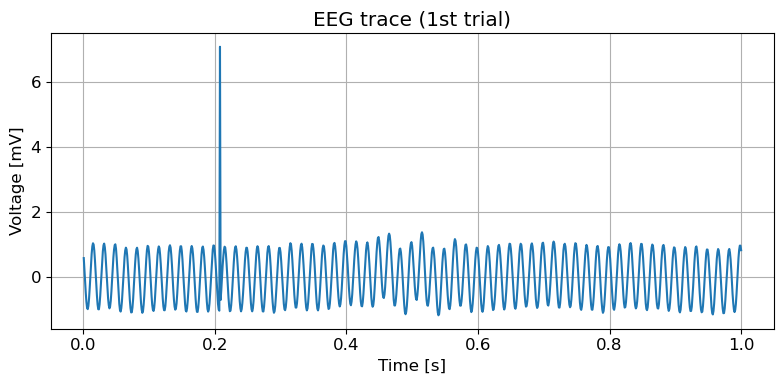

In [2]:
# Base directory = folder where this notebook lives
base_dir = Path().resolve()

data_file = base_dir / "chapter6_Data" / "Ch6-EEG-1.mat"

# Load MATLAB file
data = loadmat(data_file)  
eeg = data['EEG']            # Extract the EEG variable
t = data['t'][0]             # ... and the t variable
n_trials, n_samples = eeg.shape
print(f"EEG data shape: {eeg.shape} (samples × trials)")
print(f"Number of samples: {n_samples}")
print(f"Number of trials: {n_trials}")

plt.figure
plt.plot(t, eeg[0])
plt.xlabel("Time [s]")
plt.ylabel("Voltage [mV]")
plt.title("EEG trace (1st trial)")
plt.tight_layout()
plt.show()

The variable `eeg` is a matrix array, whith each row corresponding to a single trial. Every trial contains 1000 samples (sampling frequency: 1000 Hz). Visual stimulus was presented at the beginning of the trial (at time 0.001 s, corresponding to the index 0 of variable `t`).\
Visual inspection of the first trial reveals two clear features. A fast oscillatory component is visible, with an amplitude of roughly 1 mV. In addition, there is a prominent voltage deflection around 0.2 s. Slower fluctuations may also be present, though they are harder to identify by eye.
As in the first tutorial, we calculate the power spectrum, this time using a **Hann taper**:

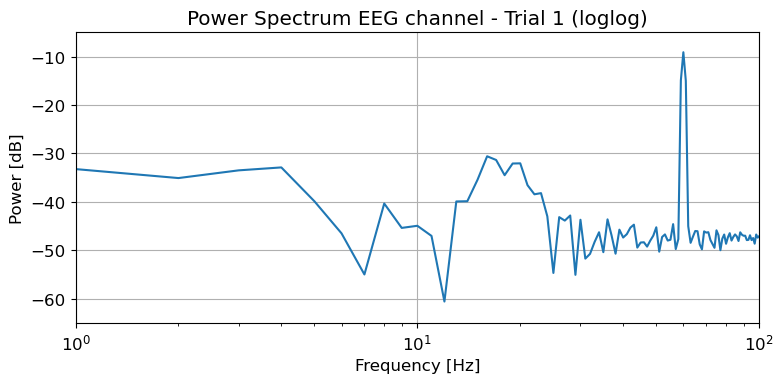

In [3]:
x = eeg[0]                # Load the first trial.
x = x - x.mean()          # Subtract the mean from the data.
dt = t[1] - t[0]          # Define the sampling interval.
N = len(x)                # Define the number of points in the trial.
T = N* dt                 # define the duration of the trial

xh = np.hanning(N) * x       # Multiply data by Hanning window,
xf = np.fft.fft(xh)        # ... compute Fourier transform,
Sxx = 2 * dt ** 2 / T * (xf * xf.conj());  #... and compute spectrum.
 
df = 1 / T;                     # Determine frequency resolution.
fNQ = 1 / dt / 2;               # Determine Nyquist frequency.
faxis = arange(0, fNQ, df)      # Construct frequency axis
Sxx_pos = Sxx[:len(faxis)]      # keep non-negative frequencies

plt.semilogx(faxis, 10 * np.log10(Sxx_pos.real))
plt.xlim(1, 100)
plt.ylim(-65,-5)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Power Spectrum EEG channel - Trial 1 (loglog)")
plt.tight_layout()
plt.show()

**Description**: The power spectral density shows higher power at low frequencies and progressively lower power at higher frequencies—a characteristic pattern of EEG signals. The spectrum also reveals a prominent peak at 60 Hz, matching the dominant oscillation seen during visual inspection. This peak reflects electrical line noise, which appears at 60 Hz in recordings made in the United States. Additionally, a second peak is visible between 15 and 30 Hz, indicating the presence of another rhythmic component in this range.

**Task**: Use the same code to examine two additional trials from the `eeg` variable. Briefly describe what you observe.

### Evoked Response and Average Spectrum
A first look at the individual EEG trials is not very promising: the signals are dominated by 60 Hz line noise and occasional large deflections, making it difficult to see any evoked response. If a stimulus-locked response exists, it is likely weak and not visible in single trials. To reveal such a response, we can average the EEG across trials, thereby reducing unrelated activity and enhancing stimulus-evoked components. We therefore compute the trial-averaged signal along with its standard deviation at each time point.

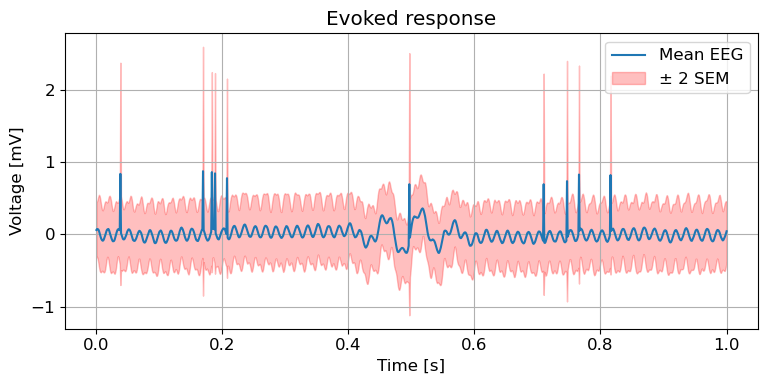

In [4]:
n_trials = eeg.shape[0]                # number of trials

mn = eeg.mean(axis=0)                  # ERP
sd = eeg.std(axis=0)                   # standard deviation across trials
sem = sd / np.sqrt(n_trials)           # standard error of the mean (SEM)

plt.figure()
plt.plot(t, mn, label="Mean EEG")      # ERP

# Shaded confidence band (± 2 SEM)
plt.fill_between(t,
                 mn - 2 * sem,
                 mn + 2 * sem,
                 color='red',
                 alpha=0.25,
                 label="± 2 SEM")

plt.xlabel("Time [s]")
plt.ylabel("Voltage [mV]")
plt.title("Evoked response")
plt.legend()
plt.tight_layout()
plt.show()

Visual inspection highlights three main points. The 60 Hz noise that dominated single trials is now much weaker. There are several brief voltage deflections throughout the epoch (e.g., around 0.2 s and 0.8 s). Most notably, a short burst of rhythmic activity appears near 0.5 s—about two cycles in 125 ms, roughly 16 Hz—suggesting a possible evoked response. However, because the 95% confidence band still includes zero, we do not have evidence for a statistically significant ERP.

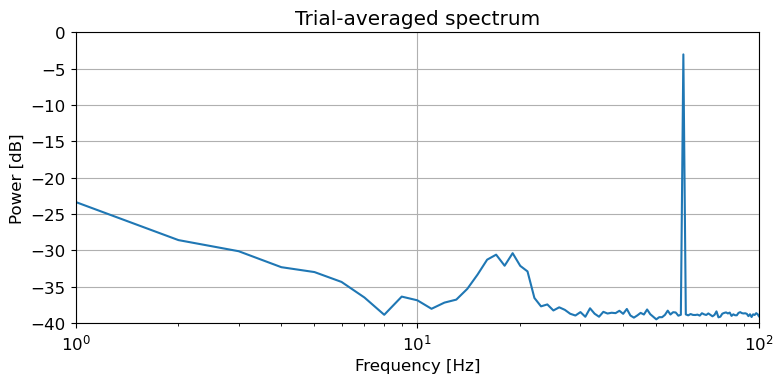

In [5]:
# trial-averaged spectrum 

def spectrum(x, t, use_hann=True):
    """
    Compute the power spectrum of a single trial x
    given the time vector t.
    """
    dt = t[1] - t[0]                 # Sampling interval
    T  = len(t) * dt                 # Total duration
    N  = len(x)                      # Number of samples

    x = x - x.mean()                 # Remove DC offset
    window = np.hanning(N) if use_hann else np.ones(N)
    xw = window * x                  # Apply window

    xf = np.fft.rfft(xw)             # One-sided FFT
    Sxx = 2 * (dt**2) / T * (xf * np.conj(xf))

    return Sxx.real


# Compute spectrum for each trial
Sxx = np.array([spectrum(trial, t, use_hann=False) for trial in eeg])

# Trial-averaged spectrum
Sxx_mean = Sxx.mean(axis=0)

# Frequency axis (consistent with rfft)
freqs = np.fft.rfftfreq(len(t), d=t[1] - t[0])

plt.figure()
plt.semilogx(freqs, 10 * np.log10(Sxx_mean))
plt.xlim([freqs[1], 100])
plt.ylim([-40, 0])
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Trial-averaged spectrum")
plt.tight_layout()
plt.show()


Note: In the code, the single-trial spectrum is computed without a **Hanning taper**. Explore what happens when you enable it by changing the parameter from `False` to `True` in line 23. Describe how the spectrum changes.\
In conclusion, averaging the spectra across trials reduces variability, making the rhythmic peak in the 15–25 Hz range more visible. The 60 Hz electrical noise remains prominent, and the overall decrease in power with increasing frequency mirrors what we saw in single-trial spectra. Taken together, the single-trial and averaged results indicate that the EEG is strongly dominated by 60 Hz line noise. Although there are hints of a possible evoked response, the evidence is not conclusive. Reducing the 60 Hz contamination may help reveal a weak response that is currently obscured, so we next attempt to **filter the data**.
## Naive Filtering
In the next section, we follow the approach of *Kramer & Eden* to introduce the basic idea of filtering. Python packages such as `scipy` offer many filtering tools, but before using them blindly, it is essential to understand how a filter actually works. To build this intuition, we construct a simple *naive filter*.  

Our signal contains a strong 60 Hz component. In principle, we could take the Fourier transform, inspect the power spectrum, identify the 60 Hz peak, remove it, and then apply the inverse Fourier transform to reconstruct a “cleaned” signal. We call this a *naive rectangular filter*: *naive* because it directly removes a frequency component based on intuition, and *rectangular* because it eliminates that component abruptly in the frequency domain.

Symbolically:

**Fourier Transform**  
$X_n \;\xrightarrow{\mathrm{FT}}\; X_j$

where $X_n$ is the time-domain signal and $X_j$ its frequency-domain representation. After removing the 60 Hz contribution, we return to the time domain using the inverse Fourier transform:

**Inverse Fourier Transform**  
$X_n \;\xleftarrow{\mathrm{iFT}}\; X_j$

This simple procedure illustrates the core idea behind filtering and prepares us to understand more refined methods.
### Step 1
Here we compute the Fourier transform of the data . We will focus on one trial:

In [6]:
# Select trial 1 and remove its mean, then compute its Fourier transform
x = eeg[0, :]                # Data from trial 1
x = x - x.mean()             # Subtract the mean
xf = np.fft.fft(x)           # Compute the Fourier transform


### Step 2
The vector `xf`, which contains the complex Fourier coefficients, has the **same length** as the time-domain data from trial 1 (`x`). To identify the index corresponding to 60 Hz, we use the NumPy function `np.fft.fftfreq`, which returns the frequency values (both positive and negative) associated with each Fourier coefficient. Conceptually, this mapping is similar to wrapping frequencies around a circle, spanning the range from $-\pi$ to $\pi$.

The next cell constructs the frequency axis (`faxis`), and the following one visualizes it.

In [7]:
# Define sampling interval and frequency axis for trial 1
dt = t[1] - t[0]                  # Sampling interval
N = len(x)                        # Number of samples in the trial
faxis = np.fft.fftfreq(N, d=dt)   # Frequency axis


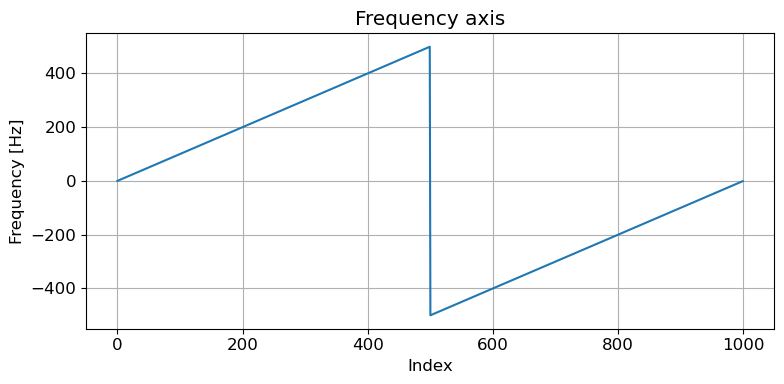

In [8]:
plt.figure()
plt.plot(faxis)
plt.ylabel("Frequency [Hz]")
plt.xlabel("Index")
plt.title("Frequency axis")
plt.tight_layout()
plt.show()

Now, we search for the indices of 60 Hz at both, the positive and negative side of the spectrum:

In [9]:
# Find indices of frequency components near 60 Hz
indices = (np.abs(faxis) >= 59) & (np.abs(faxis) <= 61)


Now that we have identified the indices around 60 Hz, we can remove the line noise by zeroing out those frequency components. We do this by creating a frequency-domain filter that equals 1 everywhere except at ±60 Hz, where it is set to 0. Multiplying this filter by the Fourier coefficients `xf` suppresses the 60 Hz components while leaving all other frequencies unchanged.

The next cell visualizes what the rectangular filter looks like.

In [10]:
# Define a rectangular filter in the frequency domain
rectangular_filter = np.ones_like(xf)      # Start with gain = 1 at all frequencies
rectangular_filter[indices] = 0            # Set gain = 0 near the line-noise frequencies

# Apply the filter to the Fourier coefficients
xf_filtered = xf * rectangular_filter


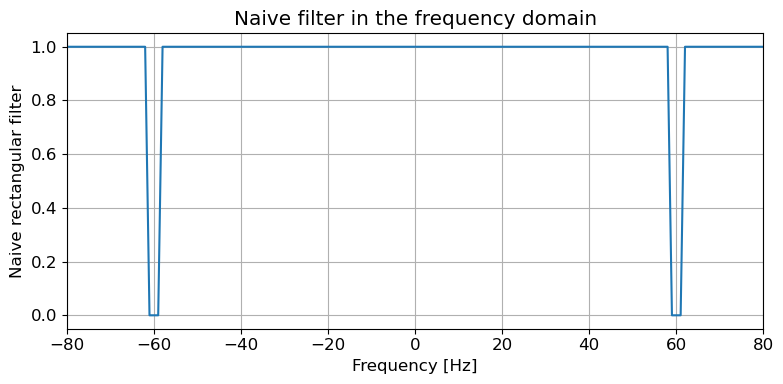

In [11]:
# Sort frequency axis for plotting
isorted = np.argsort(faxis)

plt.figure()
plt.plot(faxis[isorted], rectangular_filter[isorted].real) #here we only plot the real part
plt.xlabel("Frequency [Hz]")
plt.ylabel("Naive rectangular filter")
plt.title("Naive filter in the frequency domain")
plt.xlim([-80, 80])
plt.tight_layout()
plt.show()


The next cell builds a simple rectangular filter in the frequency domain that sets the 60 Hz components to zero and then applies it to the Fourier coefficients, effectively removing the 60 Hz line noise from the signal in frequency space. The next cell visualizes this effect comparing the power spectrum (positive and negative frequencies) **before** and **after** the filtering.

In [27]:
# Define a real-valued rectangular filter in the frequency domain
rectangular_filter = np.ones_like(xf, dtype=float)   # Gain = 1 at all frequencies
rectangular_filter[indices] = 0                      # Set gain = 0 near line-noise frequencies

# Apply the filter to the Fourier coefficients
xf_filtered = xf * rectangular_filter


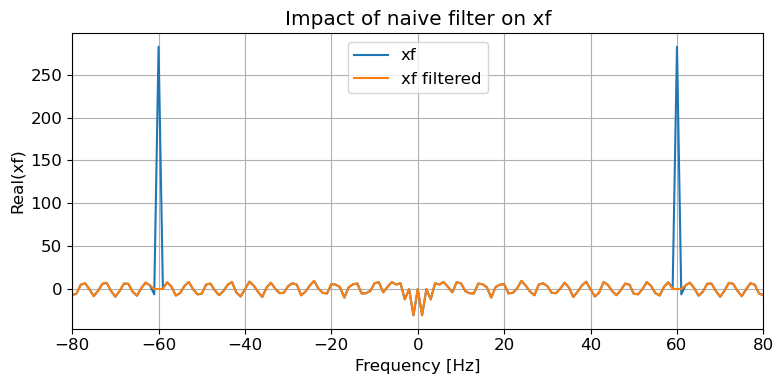

In [28]:
plt.figure()

# Plot real part of original Fourier coefficients
plt.plot(faxis[isorted], xf.real[isorted], label="xf")

# Plot real part after filtering
plt.plot(faxis[isorted], xf_filtered.real[isorted], label="xf filtered")

plt.xlabel("Frequency [Hz]")
plt.ylabel("Real(xf)")
plt.title("Impact of naive filter on xf")
plt.xlim([-80, 80])
plt.legend()
plt.tight_layout()
plt.show()


### Step 3
Now, we apply the inverse Fourier transform of the filtered data and obtain the representation inthe time domain.

In [29]:
# Inverse Fourier transform: go back to the time domain after filtering
xnew = np.fft.ifft(xf_filtered)

Now, let's visualize how the `xnew` filtered data looks like:

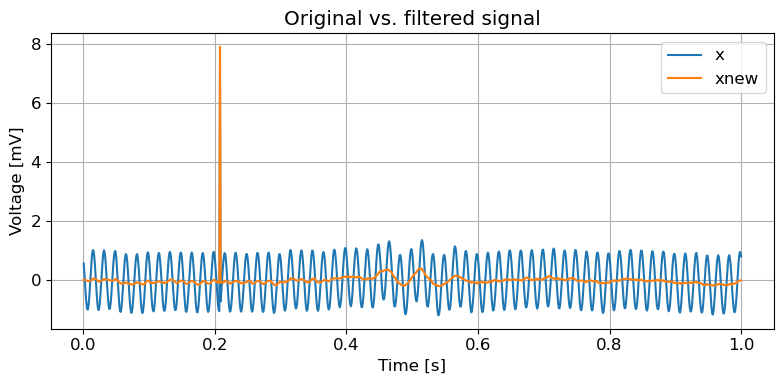

In [30]:
# Keep only the real part (imaginary part is numerical noise)
xnew = xnew.real

# Plot original and filtered signals
fig, ax = plt.subplots()
ax.plot(t, x, label="x")        # Original signal
ax.plot(t, xnew, label="xnew")  # Filtered signal

ax.set_xlabel("Time [s]")
ax.set_ylabel("Voltage [mV]")
ax.set_title("Original vs. filtered signal")
ax.legend()

plt.tight_layout()
plt.show()


The noise at 60 Hz is reduced. The same is true in the frequency domain.

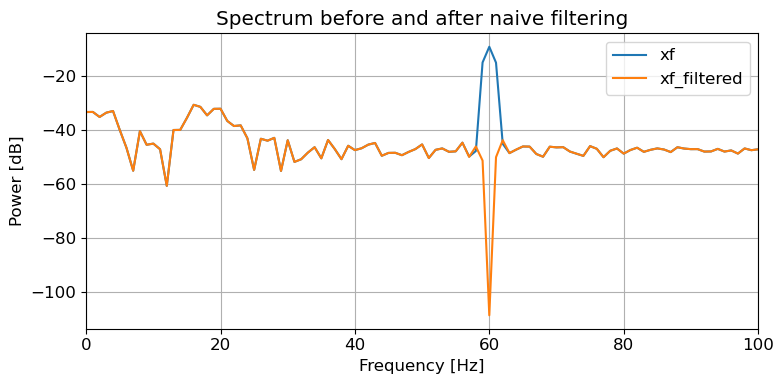

In [31]:
# Compute spectra
Sxx_x     = spectrum(x, t)       # unfiltered
Sxx_xnew  = spectrum(xnew, t)    # filtered

# Frequency axis consistent with rfft output
dt = t[1] - t[0]
freqs = np.fft.rfftfreq(len(x), d=dt)

plt.figure()
plt.plot(freqs, 10 * np.log10(Sxx_x),    label="xf")          # Unfiltered
plt.plot(freqs, 10 * np.log10(Sxx_xnew), label="xf_filtered") # Filtered

plt.xlim([0, 100])
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Spectrum before and after naive filtering")
plt.legend()
plt.tight_layout()
plt.show()


These initial results suggest that the naive filter is successfully removing the 60 Hz component. However, something subtle is happening. To see this, we zoom in on the filtered signal around the brief, large voltage deflection at approximately $(t \approx 0.2 \text{s})$.

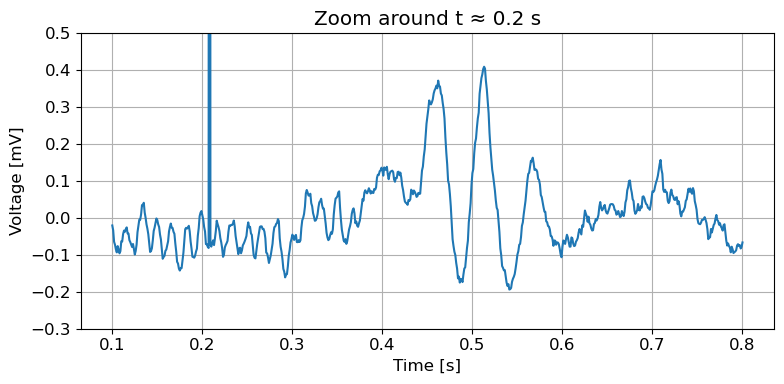

In [32]:
# Define zoom window around 0.2 s
t_min = 0.1
t_max = 0.8

zoom_idx = (t >= t_min) & (t <= t_max)

plt.figure()
plt.plot(t[zoom_idx], xnew[zoom_idx])

plt.xlabel("Time [s]")
plt.ylabel("Voltage [mV]")
plt.title("Zoom around t ≈ 0.2 s")
plt.ylim([-0.3,0.5])
plt.tight_layout()
plt.show()


A closer look shows small 60 Hz–like ripples appearing around the sharp voltage jump—well before and after the event. These transients might look biological, but they are far more likely to be artifacts introduced by our naive rectangular filter. In the next section, we examine this effect more carefully and assess the limitations of this simple filtering approach.

### Impulse Response
Up to this point, we’ve looked at the naive rectangular filter mainly in the frequency domain. To understand its behavior more completely, we now examine its **impulse response**—that is, how the filter reacts to a single, brief impulse **in time**. An impulse looks simple in the time domain, but it contains energy across all frequencies, making it a useful probe of how the filter handles broadband input. Below, we compute the impulse response for our naive filter.  

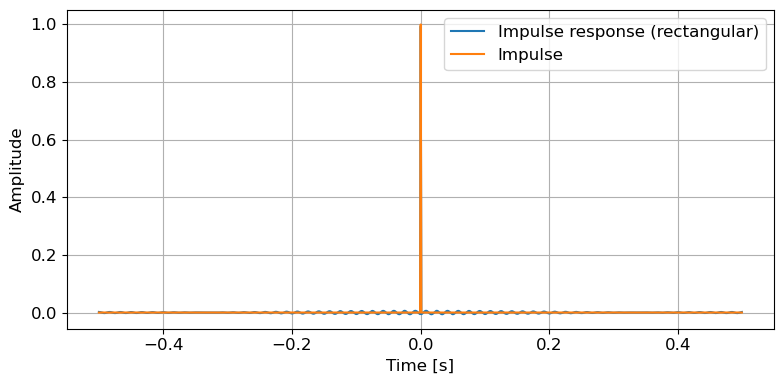

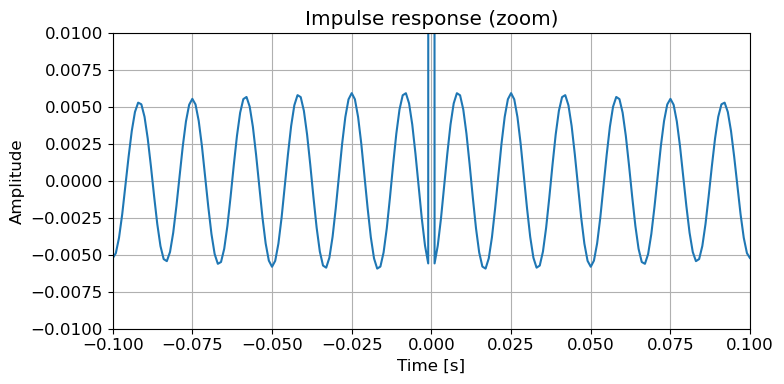

In [33]:
# Impulse response via frequency-domain multiplication
impulse = np.zeros_like(rectangular_filter)
impulse[N // 2] = 1.0  # impulse at the center

impulse_f = np.fft.fft(impulse) * rectangular_filter
impulse_response_rect = np.fft.ifft(impulse_f).real

lag_axis = (np.arange(-N // 2, N // 2) * dt)

fig, ax = plt.subplots()
ax.plot(lag_axis, impulse_response_rect, label='Impulse response (rectangular)')
ax.plot(lag_axis, impulse, label='Impulse')
ax.set_xlabel('Time [s]')
ax.set_ylabel('Amplitude')
ax.legend()
plt.tight_layout()
plt.show()

# Zoom in to reveal small oscillations around the main peak
fig, ax = plt.subplots()
ax.plot(lag_axis, impulse_response_rect)
ax.set_xlabel('Time [s]')
ax.set_ylabel('Amplitude')
ax.set_title('Impulse response (zoom)')
ax.set_ylim([-0.01, 0.01])
ax.set_xlim([-0.1, 0.1])
plt.tight_layout()
plt.show()

The rectangular notch removes 60 Hz in the frequency domain, but in the time domain its impulse response rings at 60 Hz and extends across the entire signal. This explains the long-lasting 60 Hz ripples that appear around sharp deflections in the filtered EEG. We find that an impulse, initially localized to a single index in time in our original EEG dataset, becomes broadly distributed in time upon filtering.

### Naive Hanning (Hann) notch filter

To reduce the long-range ringing, we soften the transition around 60 Hz. Instead of a hard rectangular notch, we build a smoother **Hann-shaped notch** centered at ±60 Hz.

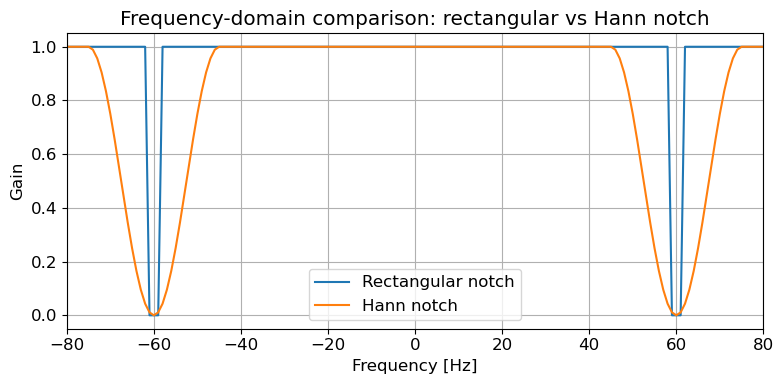

In [34]:
# Build a Hann-notch filter around ±60 Hz
df = 1.0 / (N * dt)
fNQ = 1.0 / (2.0 * dt)

win = 15  # half-width in frequency bins for the notch
inds_hann = (np.abs(faxis) >= (60 - win * df)) & (np.abs(faxis) <= (60 + win * df))

hann_filter = np.ones(N, dtype=float)
notch_shape = 1.0 - np.hanning(2 * win + 1)

# There are two symmetric 60 Hz regions: negative and positive frequencies
hann_filter[inds_hann] = np.concatenate([notch_shape, notch_shape])

order = np.argsort(faxis)
plt.figure()
plt.plot(faxis[order], rectangular_filter[order], label='Rectangular notch')
plt.plot(faxis[order], hann_filter[order], label='Hann notch')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Gain')
plt.title('Frequency-domain comparison: rectangular vs Hann notch')
plt.xlim([-80, 80])
plt.legend()
plt.tight_layout()
plt.show()

This code sets up the frequency grid and begins constructing a **Hann-shaped notch filter** around ±60 Hz:

- `df = 1.0 / (N * dt)`  
  Computes the **frequency resolution** of the FFT (distance between adjacent frequency bins).

- `fNQ = 1.0 / (2.0 * dt)`  
  Computes the **Nyquist frequency**, the highest frequency that can be represented for the given sampling rate.

- `win = 15`  
  Sets the **half-width** of the notch in terms of **frequency bins**. The full notch will span `2 * win + 1` bins around 60 Hz.

- `inds_hann = (np.abs(faxis) >= (60 - win * df)) & (np.abs(faxis) <= (60 + win * df))`  
  Creates a boolean mask selecting all frequency indices whose absolute frequency lies in a band of width `± win * df` around 60 Hz. These are the bins where the notch will be applied (both +60 Hz and −60 Hz).

- `hann_filter = np.ones(N, dtype=float)`  
  Initializes the filter in the frequency domain with **gain 1** at all frequencies (i.e., no attenuation yet).

- `notch_shape = 1.0 - np.hanning(2 * win + 1)`  
  Builds a **smooth notch profile** using a Hann window: values near the center (60 Hz) are close to 0 (strong attenuation), and values toward the edges of the band approach 1 (no attenuation). This will later be used to smoothly reduce gain around ±60 Hz instead of using a hard rectangular cut.

The next figure compares the **time-domain impulse responses** of the rectangular notch filter and the smoother Hann notch filter. In the code, we create a single-sample impulse and convolve it with each filter’s time-domain representation (obtained via the *inverse FFT*). Recall the fundamental relationship:

> **Multiplication in the frequency domain corresponds to convolution in the time domain.**

This equivalence lets us explore filtering from both perspectives: applying a filter in frequency space reveals how it behaves when convolved with an impulse in time, and examining the impulse response helps us anticipate the filter’s effects on real signals.

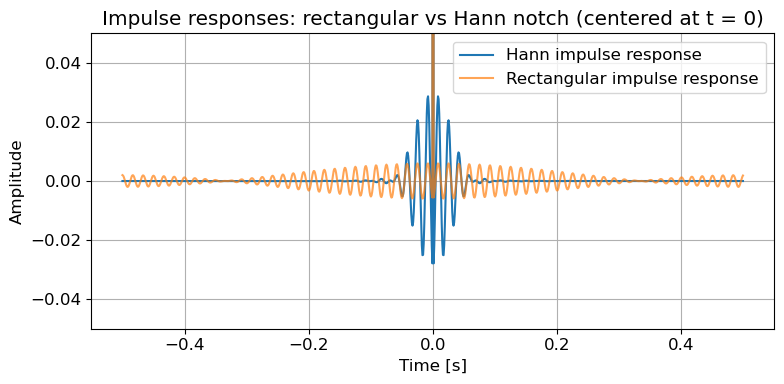

In [35]:
# Impulse responses of rectangular and Hann notch filters (via IFFT)
impulse_response_rect = np.fft.ifft(rectangular_filter).real
impulse_response_hann = np.fft.ifft(hann_filter).real

# Center them around t = 0
impulse_response_rect = np.fft.fftshift(impulse_response_rect)
impulse_response_hann = np.fft.fftshift(impulse_response_hann)

# Time axis centered at zero
N = len(impulse_response_rect)
lag_axis = (np.arange(-N // 2, N // 2) * dt)

fig, ax = plt.subplots()
ax.plot(lag_axis, impulse_response_hann, label="Hann impulse response")
ax.plot(lag_axis, impulse_response_rect, label="Rectangular impulse response", alpha=0.7)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Amplitude")
ax.set_title("Impulse responses: rectangular vs Hann notch (centered at t = 0)")
ax.set_ylim([-0.05, 0.05])
ax.legend()

plt.tight_layout()
plt.show()


Here, in lines `2` and `3` of the code, we take the **inverse FFT** of a rectangular and a Hann-notch filter. This operation gives us the *impulse response* of each filter in the time domain.\
Then, in line `6` and `7`, we use `np.fft.fftshift` to **reorder** the samples so that the *zero* (center) of the sequence is in the middle of the array.

> **Task**: Compare both impulse responses. What could you say about the *roll-off* and time-spread of both filters?

 Now, let's see what happens when we apply the Hann-notch filter to our EEG data:

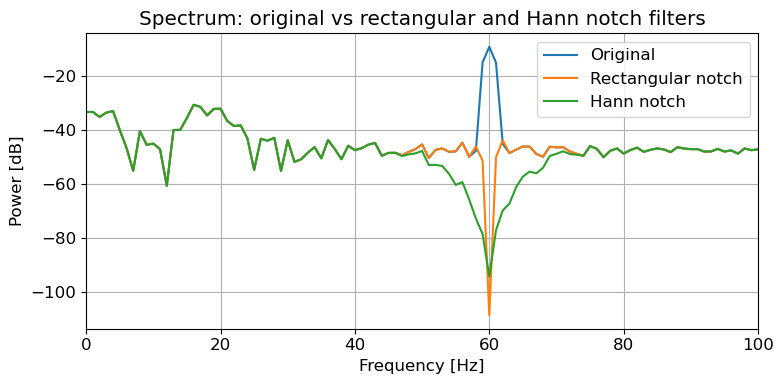

In [36]:
# Compute spectra
Sxx_orig  = spectrum(x, t)       # Unfiltered
Sxx_rect  = spectrum(x_rect, t)  # Rectangular notch
Sxx_hann  = spectrum(x_hann, t)  # Hann notch

# Frequency axis consistent with rfft output
dt = t[1] - t[0]
freqs = np.fft.rfftfreq(len(x), d=dt)

plt.figure()
plt.plot(freqs, 10 * np.log10(Sxx_orig), label="Original")
plt.plot(freqs, 10 * np.log10(Sxx_rect), label="Rectangular notch")
plt.plot(freqs, 10 * np.log10(Sxx_hann), label="Hann notch")

plt.xlim([0, 100])
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Spectrum: original vs rectangular and Hann notch filters")
plt.legend()
plt.tight_layout()
plt.show()


The figure compares the power spectra of the original EEG signal with the versions filtered by a **rectangular notch** and a **Hann notch** around 60 Hz.

- The **original spectrum** shows a clear, sharp peak at **60 Hz**, reflecting strong line noise, and an overall decrease in power with increasing frequency.
- The **rectangular notch** almost completely removes the 60 Hz peak, but does so with a very abrupt transition in frequency.
- The **Hann notch** also suppresses the 60 Hz component, but with a smoother, rounded “dip” instead of a sharp cut.

In other words, both filters reduce the 60 Hz noise, but the Hann notch does it more gently in the frequency domain, which (as seen from the impulse responses) leads to a more localized and better-behaved effect in the time domain.


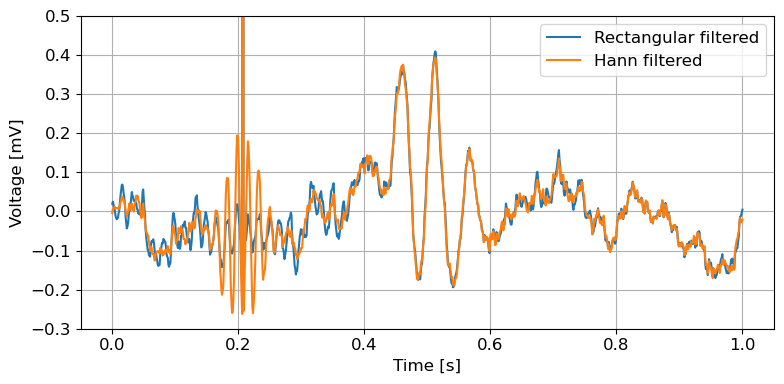

In [26]:
# Apply rectangular and Hann notch filters to the EEG trial
xf = np.fft.fft(x)

xf_rect = xf * rectangular_filter
x_rect = np.fft.ifft(xf_rect).real

xf_hann = xf * hann_filter
x_hann = np.fft.ifft(xf_hann).real

plt.figure()
plt.plot(t, x_rect, label='Rectangular filtered')
plt.plot(t, x_hann, label='Hann filtered')
plt.xlabel('Time [s]')
plt.ylabel('Voltage [mV]')
plt.ylim([-0.3, 0.5])
plt.legend()
plt.tight_layout()
plt.show()

This figure shows the **time-domain effect** of the two notch filters on the same EEG trial:

- The **rectangular-filtered** trace removes the 60 Hz component, but introduces long-lasting 60 Hz–like ripples that extend well before and after sharp voltage changes. This reflects the broad, slowly decaying impulse response of the rectangular notch.

- The **Hann-filtered** trace also suppresses the 60 Hz noise, but the oscillations around sharp deflections are shorter and more confined in time. This is consistent with the more compact impulse response of the Hann notch.

Both filters target the same frequency band, but the Hann notch produces a “cleaner” correction in time, with less extended ringing around transient events.

In summary, both naive filters succeed in suppressing the 60 Hz component, but they also introduce unwanted distortions. The rectangular notch performs well in the frequency domain, yet its time-domain behavior is unacceptable, adding long-lasting oscillations that can mislead our interpretation of the EEG. The Hann notch behaves more gracefully, but it still produces artifacts around sharp transients and is not a reliable choice for real analyses. Overall, while these filters are useful for building intuition, practical work should rely on well-designed filtering tools from established signal-processing libraries. The next section introduces one such example.
## Sophisticated Filtering (Finite Impulse Response - FIR)

Up to now, we built two filters directly in the **frequency domain** mainly to develop intuition.It helps clarify how filtering works, but these naive filters (rectangular or Hann notch) should **not** be used in real analyses. They distort the signal in ways that can mislead interpretation.

In practice, filtering should rely on **established filter-design tools** rather than hand-crafted spectral manipulations. The next section introduces one such approach: the **finite impulse response (FIR) filter**, which is widely used in neuroscience. Unlike our naive filters—whose impulse responses extend indefinitely—an FIR filter has a **limited, well-controlled impulse response**, avoiding long-range ringing artifacts.

One could imagine creating a FIR filter by truncating the impulse responses of our earlier filters, but there is no need to reinvent the wheel. Instead, we take advantage of tested implementations, such as `firwin()` from `scipy.signal`, to design a low-pass FIR filter. We then apply it, examine its impulse response and frequency response, and evaluate its behavior on our EEG data.

To apply our FIR filter in the time domain, we need to **convolve** the signal with the filter kernel. Normally we would just use a built-in function (e.g. from `scipy.signal`), but here we write a small helper ourselves so you can see what’s going on under the hood.

For simplicity, we use a **circular** version of convolution: when the index goes past the end of the signal, it wraps around to the beginning. You don’t need to master circular convolution here; you can simply read this function as “a manual implementation of filtering by convolution.”


In [37]:
# Helper: circular convolution (for didactic purposes)
def circular_convolution(signal, kernel):
    """Simple circular convolution: both inputs must have the same length."""
    signal = np.asarray(signal)
    kernel = np.asarray(kernel)
    N = len(signal)
    out = np.zeros(N, dtype=float)
    for ii in range(N):
        idx = (np.arange(N) - ii) % N
        out[ii] = np.sum(signal[idx] * kernel)
    return out


Here we design and inspect a **low-pass FIR filter** that keeps activity below 30 Hz.

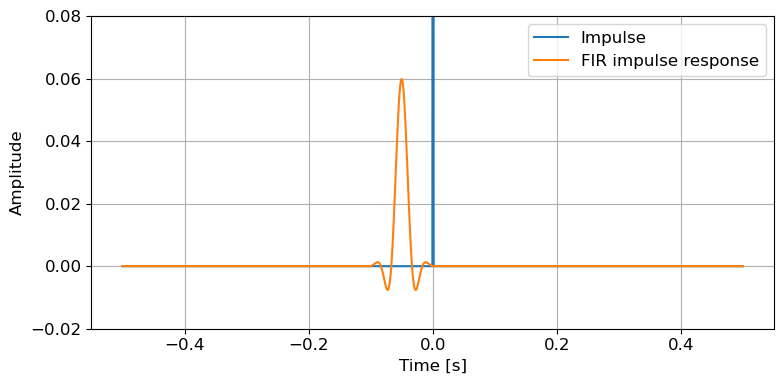

In [42]:
# Design a low-pass FIR filter (cutoff 30 Hz)
n_order = 100                # filter order (number of taps)
Wn = 30.0 / fNQ              # normalized cutoff (fraction of Nyquist)
b = firwin(n_order, Wn)      # FIR low-pass filter coefficients

# Pad with leading zeros so that length matches N
bz = np.pad(b, (N - n_order, 0), mode='constant')

# Impulse response via circular convolution
impulse_response_fir = circular_convolution(impulse, bz)

plt.figure()
plt.plot(lag_axis, impulse, label='Impulse')
plt.plot(lag_axis, impulse_response_fir, label='FIR impulse response')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.ylim([-0.02, 0.08])
plt.legend()
plt.tight_layout()
plt.show()

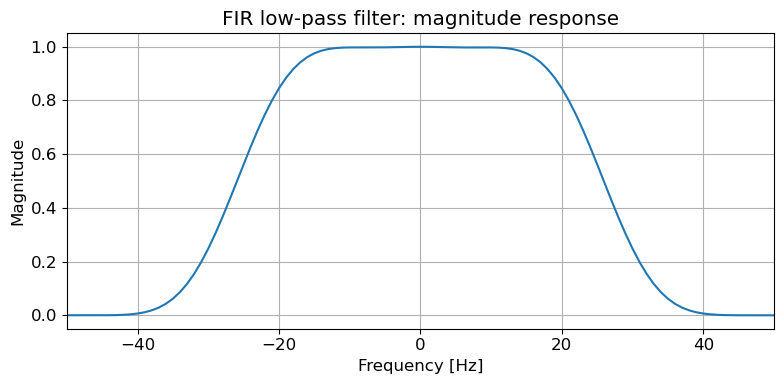

In [43]:
# Magnitude response of the FIR filter in the frequency domain
bf = np.fft.fft(b, N) #Transform the coefficients of the filter ("b") into the frequency domain 
Mb = (bf * np.conj(bf)).real

order = np.argsort(faxis)
plt.figure()
plt.plot(faxis[order], Mb[order])
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')
plt.title('FIR low-pass filter: magnitude response')
plt.xlim([-50, 50])
plt.tight_layout()
plt.show()

Before we dive into the FIR code, it’s useful to be explicit about **what signals we are working with** in this figure:

- First, we create an **artificial impulse** in time:
  - a vector that is zero everywhere except at a single sample, where it is 1.
  - This is *not* EEG data; it is a simple test signal we build on purpose.

- Then we **pass this impulse through the FIR filter** using convolution.
  - The output is the **impulse response** of the FIR filter.
  - In other words: it shows how the filter reacts to a single, sharp event.

When we plot the impulse and the FIR impulse response together, we are comparing:
- the ideal, instantaneous event (the impulse), and  
- how the FIR filter spreads this event over time (its impulse response).

With that in mind, we can now look at the code that designs the FIR filter and computes its impulse response.

### What are we doing here?
1. Choosing the filter order (`n_order`)\
The order (or number of *taps* set the **length of the FIR filter in time**. A longer filter gives a sharper frequency cutoff (better separation of <30 Hz vs >30 Hz), but spreads its influence over a longer window and introduces more delay. In this case, 100 is a reasonable compromise.
2. Defining the cutoff frequency (`Wn`)\
The cutoff is usually expressed as **a fraction of the Nyquist frequency**.
$$ W_n = \frac{30 \text{Hz}}{f_\text{Nyquist}} $$
In other words, it tells `firwin ()` where to put the low-pass boundary.
3. Designing the FIR filter (`b=firwin(...)`)\
`firwin` returns **the impulse response** of a low-pass FIER filter with
- cutoff at 30 Hz
- length 100 samples
-  linear phase (important for neural data)

Thus, the vector `b` contains the filter's weights.

To implement the **circular convolution**, our function assumes that both the filter and the signal have the same length. As the filter only has 100 samples, we **padding `b` with zeros**. The result `bz` is the FIR filter embedded in a longer vector.

> This code designs a 30 Hz low-pass FIR filter, embeds it to match the signal length, and computes its impulse response so we can examine how localized and well-behaved it is in the time domain.

#### FIR filter delay

Our FIR filter does **not** change the shape of the signal, but it **shifts it in time**.

Because the filter uses a window of 100 samples (100 taps), it needs to “look” a bit **into the past** and a bit **into the future** around each point. As a result, the output is aligned with the **center** of that window, not with the original impulse.

For a 100-tap filter, this shift is about:

- 100 / 2 = **50 samples**  
- at 1000 Hz → **50 ms delay**

So in the plot, the FIR impulse response appears **to the right** of the impulse because the filter introduces a fixed delay of about 50 ms.

#### FIR filter magnitude

In the next figure, we look at the FIR filter in the **frequency domain**. The code takes the filter coefficients `b`, computes their Fourier transform, and then uses the product with its complex conjugate to obtain the **magnitude response** (analogous to how we compute power spectra for signals).

This magnitude response shows how strongly the filter passes or suppresses each frequency. You can clearly see the **cutoff around 30 Hz**: frequencies below this point are preserved, while frequencies above it are increasingly attenuated, eventually approaching zero.

Now, we are going to apply this filter to the EEG data, using the `circular_convolution` function we created:

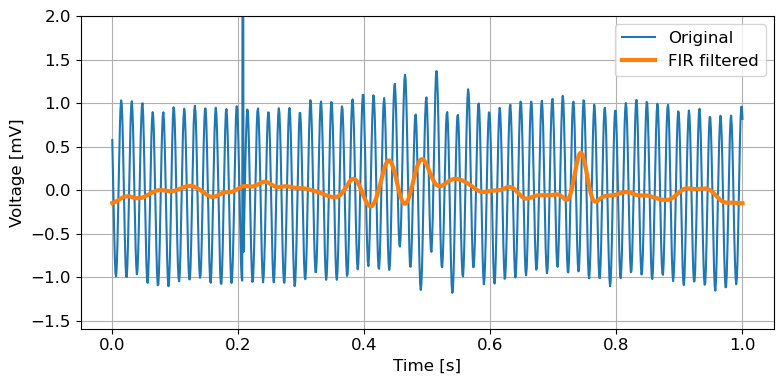

In [44]:
# Apply the FIR filter to the EEG trial
x_fir_conv = circular_convolution(x, bz)

plt.figure()
plt.plot(t, x, label='Original')
plt.plot(t, x_fir_conv, label='FIR filtered', linewidth=3)
plt.xlabel('Time [s]')
plt.ylabel('Voltage [mV]')
plt.ylim(top=2)
plt.legend()
plt.tight_layout()
plt.show()

When we inspect the FIR-filtered signal, several improvements become clear. Most noticeably, the 60 Hz line noise has been greatly reduced. With this interference removed, a brief oscillatory pattern around 0.5 s becomes visible. As expected for a low-pass filter, the spectrum is now dominated by activity below 30 Hz, with higher frequencies strongly attenuated.

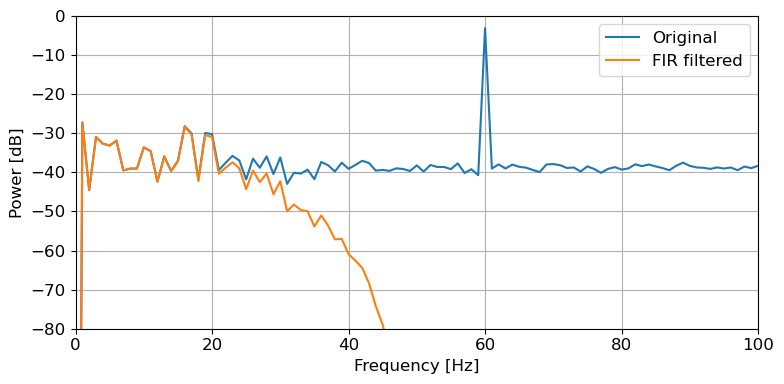

In [45]:
# Spectrum before and after FIR filtering
def spectrum_single(x, t):
    dt_local = t[1] - t[0]
    T_local = len(t) * dt_local
    x0 = x - x.mean()
    xf_local = np.fft.rfft(x0)
    Sxx = 2 * (dt_local**2) / T_local * (xf_local * np.conj(xf_local))
    freqs = np.fft.rfftfreq(len(t), d=dt_local)
    return freqs, Sxx.real

freqs, Sxx_orig = spectrum_single(x, t)
_, Sxx_fir = spectrum_single(x_fir_conv, t)

plt.figure()
plt.plot(freqs, 10 * np.log10(Sxx_orig), label='Original')
plt.plot(freqs, 10 * np.log10(Sxx_fir), label='FIR filtered')
plt.xlim([0, 100])
plt.ylim([-80, 0])
plt.xlabel('Frequency [Hz]')
plt.ylabel('Power [dB]')
plt.legend()
plt.tight_layout()
plt.show()

now, let's compare the three filtering methods:

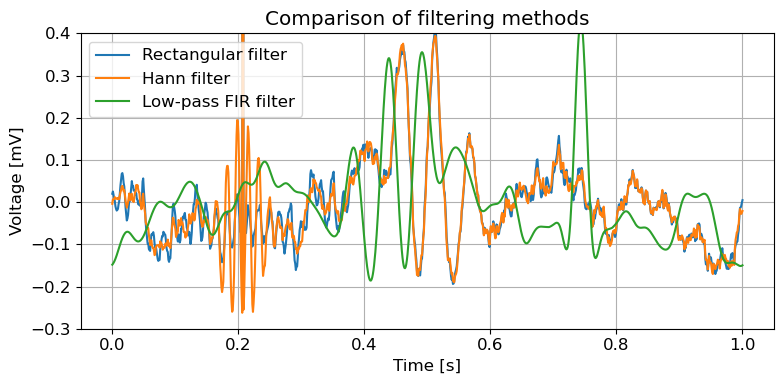

In [46]:
plt.figure()

plt.plot(t, x_rect,       label="Rectangular filter")
plt.plot(t, x_hann,       label="Hann filter")
plt.plot(t, x_fir_conv,   label="Low-pass FIR filter")

plt.ylim([-0.3, 0.4])
plt.xlabel("Time [s]")
plt.ylabel("Voltage [mV]")
plt.title("Comparison of filtering methods")
plt.legend()

plt.tight_layout()
plt.show()

This figure compares how three different filters modify the same EEG trial in the **time domain**:

- **Rectangular filter**  
  Strongly removes the 60 Hz component, but introduces long-lasting 60 Hz–like ringing around sharp events. The signal looks visibly distorted around transients.

- **Hann filter**  
  Also suppresses 60 Hz, with less aggressive ringing than the rectangular filter. The distortion around sharp deflections is still present, but more localized in time.

- **Low-pass FIR filter**  
  Reduces high-frequency noise (including 60 Hz) while producing a smoother trace dominated by slower components. The waveform is shifted slightly in time (filter delay), but shows fewer artifacts around sharp events.

Overall, all three filters attenuate the unwanted 60 Hz activity, but the FIR filter does so in a more controlled and interpretable way, with fewer distortions in the time domain.

So far, we have applied our FIR filter using a custom convolution function, mainly to build intuition. In practice, however, it is much more convenient (and safer) to use well-tested library functions such as `scipy.signal.lfilter`, which apply the filter directly to the data in a single line of code.

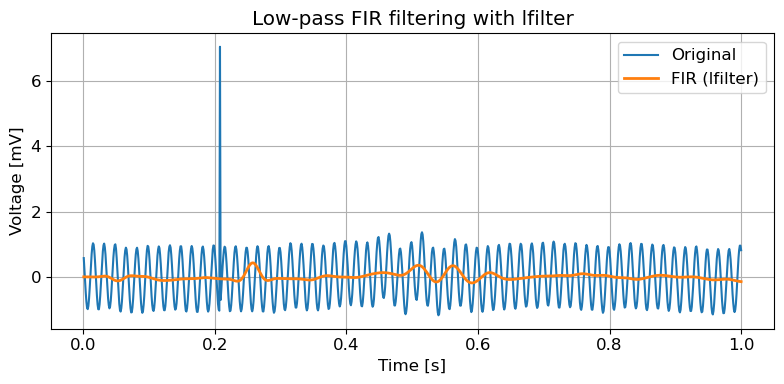

In [48]:
# 1. Design a low-pass FIR filter (cutoff 30 Hz)
n_order = 101                      # number of taps (odd is convenient)
cutoff = 30.0                      # Hz
Wn = cutoff / fNQ                  # normalized cutoff (0–1, fraction of Nyquist)

b = firwin(n_order, Wn)            # FIR low-pass coefficients
a = 1.0                            # FIR filter → denominator is 1

# 2. Apply the filter with lfilter
x_fir_lf = lfilter(b, a, x)        # filtered signal

# 3. Plot original vs filtered
plt.figure()
plt.plot(t, x,          label="Original")
plt.plot(t, x_fir_lf,   label="FIR (lfilter)", linewidth=2)
plt.xlabel("Time [s]")
plt.ylabel("Voltage [mV]")
plt.title("Low-pass FIR filtering with lfilter")
plt.legend()
plt.tight_layout()
plt.show()

## Phase and zero-phase filtering

So far, we focused mostly on **what** the filter does in the frequency and time domains (magnitude and impulse response).  
However, filters also affect the **phase** of different frequency components. This matters a lot when we care about the *timing* of neural events (e.g. evoked responses, functional connectivity analyses, etc.).

In this section we:

- look at the **phase response** of our low-pass FIR filter,
- see how it induces a **delay** in the signal,
- and then remove that delay using **zero-phase filtering** (`filtfilt`).

### Phase response of the low-pass FIR filter

We redesign the same low-pass FIR filter (cutoff 30 Hz), transform its coefficients to the frequency domain, and look at the **phase** as a function of frequency.

The phase response tells us how much each frequency component is advanced or delayed by the filter.

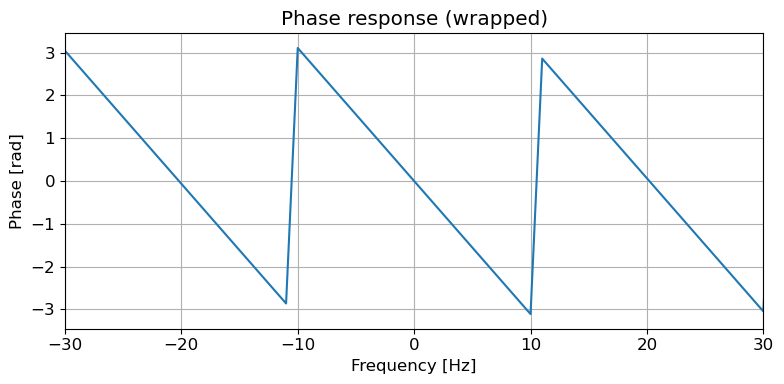

In [50]:
# --- Use first trial and basic parameters (dataset already in memory) ---

x = eeg[0, :] if eeg.ndim == 2 else eeg[0]

# Frequency axis (for filter visualization)
faxis = np.fft.fftfreq(N, d=dt)
sort_order = np.argsort(faxis)

# Design the same low-pass FIR filter (cutoff 30 Hz)
n_order = 100          # number of taps
cutoff = 30.0          # Hz
Wn = cutoff / fNQ      # normalized cutoff (fraction of Nyquist)

b = firwin(n_order, Wn)   # FIR coefficients

# --- Phase response (wrapped) ---
bf = np.fft.fft(b, N)     # FFT of filter, zero-padded to length N

plt.figure()
plt.plot(faxis[sort_order], np.angle(bf[sort_order]))
plt.xlim([-30, 30])
plt.xlabel("Frequency [Hz]")
plt.ylabel("Phase [rad]")
plt.title("Phase response (wrapped)")
plt.tight_layout()
plt.show()

The wrapped phase response is hard to read because of the jumps at \(-\pi\) and \(\pi\).  
We therefore **unwrap** the phase to reveal the underlying smooth, approximately linear phase shift.

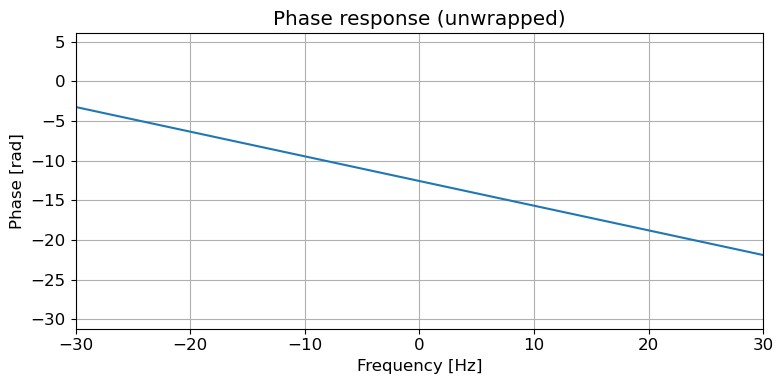

In [51]:
plt.figure()
plt.plot(faxis[sort_order], np.unwrap(np.angle(bf[sort_order])))
plt.xlim([-30, 30])
plt.xlabel("Frequency [Hz]")
plt.ylabel("Phase [rad]")
plt.title("Phase response (unwrapped)")
plt.tight_layout()
plt.show()

The unwrapped phase response is roughly **linear** in the passband (below ~30 Hz).  

A linear phase slope corresponds to a **constant delay** in time:
- all frequencies in the passband are delayed by roughly the same amount,
- for our 100-tap filter, this is about \(n/2 \approx 50\) samples → ~50 ms.

We now look at how this phase delay appears in the filtered EEG.

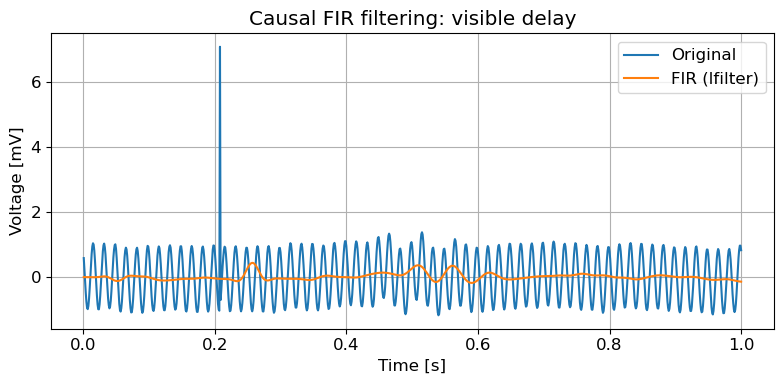

In [52]:
# --- Apply FIR with lfilter: causal, with delay ---
x_fir = lfilter(b, 1.0, x)

plt.figure()
plt.plot(t, x, label="Original")
plt.plot(t, x_fir, label="FIR (lfilter)")
plt.xlabel("Time [s]")
plt.ylabel("Voltage [mV]")
plt.title("Causal FIR filtering: visible delay")
plt.legend()
plt.tight_layout()
plt.show()

You can see that the main features of the FIR-filtered signal look similar to the original, but are **shifted to the right** (delayed) by about 50 ms. This is exactly the phase effect we saw in the impulse response.

Next, we remove this delay by applying the same filter **forwards and backwards**.

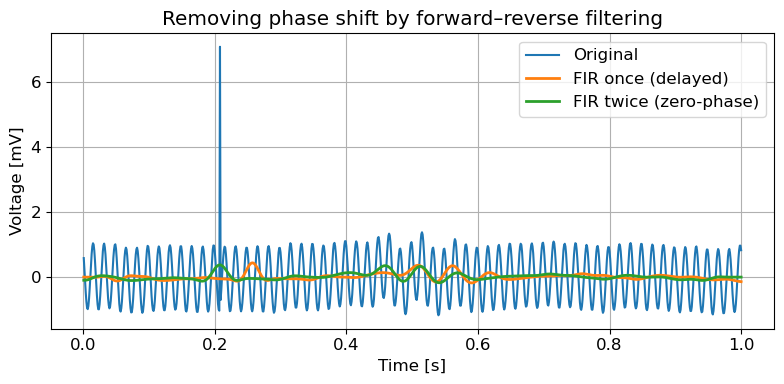

In [53]:
# --- Zero-phase filtering by hand: forward + reverse + forward + reverse ---
x1 = lfilter(b, 1.0, x)   # filter forward
x1_rev = x1[::-1]         # reverse in time
x2 = lfilter(b, 1.0, x1_rev)  # filter reversed signal
x_zero = x2[::-1]         # reverse back

plt.figure()
plt.plot(t, x, label="Original")
plt.plot(t, x_fir,      label="FIR once (delayed)", linewidth=2)
plt.plot(t, x_zero,     label="FIR twice (zero-phase)", linewidth=2)
plt.xlabel("Time [s]")
plt.ylabel("Voltage [mV]")
plt.title("Removing phase shift by forward–reverse filtering")
plt.legend()
plt.tight_layout()
plt.show()

By filtering forwards and backwards (and reversing in between), we:

- still **smooth** the signal (we apply the filter twice),
- but we **cancel out the net time shift**.

The result is a **zero-phase filtered** signal: peaks align much better with the original EEG, without the visible delay.

In practice, we do not implement this manually; we use `scipy.signal.filtfilt`, which wraps this procedure.

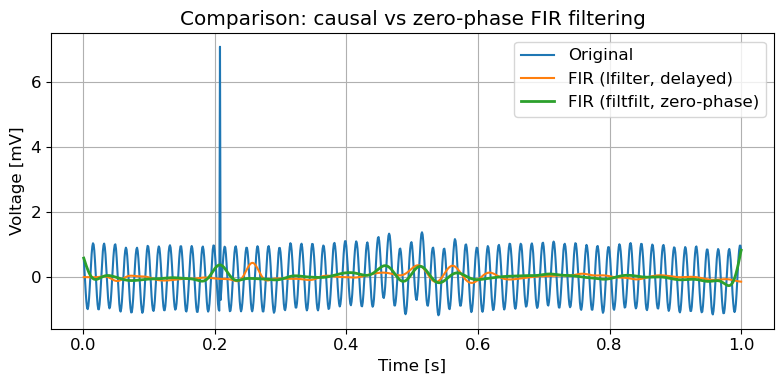

In [54]:
# --- Zero-phase filtering with filtfilt (recommended in practice) ---
x_filtfilt = filtfilt(b, 1.0, x)

plt.figure()
plt.plot(t, x,           label="Original")
plt.plot(t, x_fir,       label="FIR (lfilter, delayed)", linewidth=1.5)
plt.plot(t, x_filtfilt,  label="FIR (filtfilt, zero-phase)", linewidth=2)
plt.xlabel("Time [s]")
plt.ylabel("Voltage [mV]")
plt.title("Comparison: causal vs zero-phase FIR filtering")
plt.legend()
plt.tight_layout()
plt.show()

### Take-home messages about phase

- Our FIR low-pass filter has a **linear phase response**, which corresponds to a **constant delay** of about \(n/2\) samples.
- This delay is clearly visible when we use `lfilter` (causal filtering).
- When timing matters (e.g. evoked responses, coupling analyses), we prefer **zero-phase filtering**, which we can implement safely with:

```python
b = firwin(n_order, cutoff / fNQ)
x_filt = filtfilt(b, 1.0, x)

This keeps the amplitude behavior of the FIR filter but avoids systematic shifts in the timing of neural events.

## Analysis of the Filtered EEG Data

Now that we have introduced the key ideas behind filtering, we return to the central question: *does the EEG contain an evoked response?*  
Our earlier inspection suggested that such a response might be present but was obscured by strong 60 Hz line noise and other non-neural sources of variability.

To clarify the signal, we examine the EEG after applying a **low-pass filter**, which suppresses both the 60 Hz noise and other high-frequency artifacts (such as muscle activity). With the filtering tools now in place, designing and applying a low-pass filter with an appropriate cutoff becomes a straightforward step in our analysis.

In [56]:
####### The way you would implement a filftfilt filter

import numpy as np
from scipy.io import loadmat
from scipy.signal import firwin, filtfilt
from pathlib import Path

# Base directory = folder where this notebook lives
base_dir = Path().resolve()

data_file = base_dir / "chapter6_Data" / "Ch6-EEG-1.mat"


# Load EEG data
data = loadmat(data_file)
eeg = data["EEG"]          # shape: (trials, samples)
t = data["t"].ravel()      # time vector

# Basic sampling parameters
dt = t[1] - t[0]           # sampling interval
fNQ = 1.0 / (2.0 * dt)     # Nyquist frequency
K = eeg.shape[0]           # number of trials

# Design low-pass FIR filter (cutoff 30 Hz)
n_order = 100              # filter order (number of taps)
cutoff = 30.0              # Hz
Wn = cutoff / fNQ          # normalized cutoff (fraction of Nyquist)
b = firwin(n_order, Wn)    # FIR low-pass filter coefficients

# Zero-phase filtering of each trial
eeg_lo = np.array([filtfilt(b, 1.0, eeg[k, :]) for k in range(K)])

Here we use `firwin()` to design the FIR filter and `filtfilt()` to apply it without introducing phase shifts. Although the implementation itself is only a few lines of code, we now apply the filter with a clear understanding of its behavior—how it responds to impulses, how it shapes the amplitude spectrum, and how it affects phase. With the filtering complete, we can move on to analyzing the cleaned EEG by examining the evoked response and the average power spectrum.

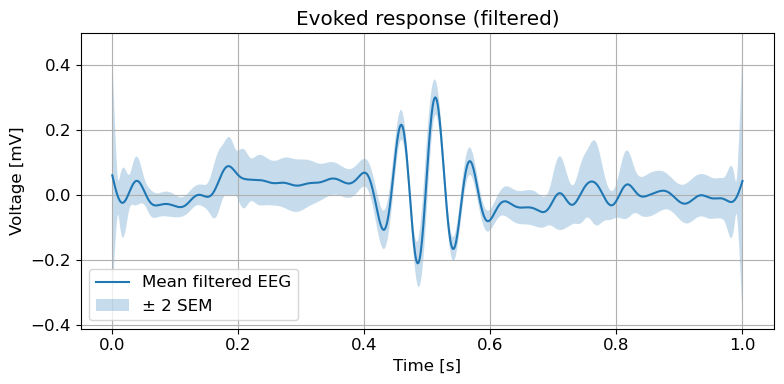

In [58]:
# Mean and variability of the filtered EEG across trials
mn = eeg_lo.mean(axis=0)            # ERP of filtered data
sd = eeg_lo.std(axis=0)             # Std across trials
sdmn = sd / np.sqrt(K)              # Std of the mean (SEM)

plt.figure()
plt.plot(t, mn, label="Mean filtered EEG")  # ERP

# Shaded confidence band (± 2 SEM)
plt.fill_between(
    t,
    mn - 2 * sdmn,
    mn + 2 * sdmn,
    alpha=0.25,
    label="± 2 SEM"
)

plt.xlabel("Time [s]")
plt.ylabel("Voltage [mV]")
plt.title("Evoked response (filtered)")
plt.legend()
plt.tight_layout()
plt.show()

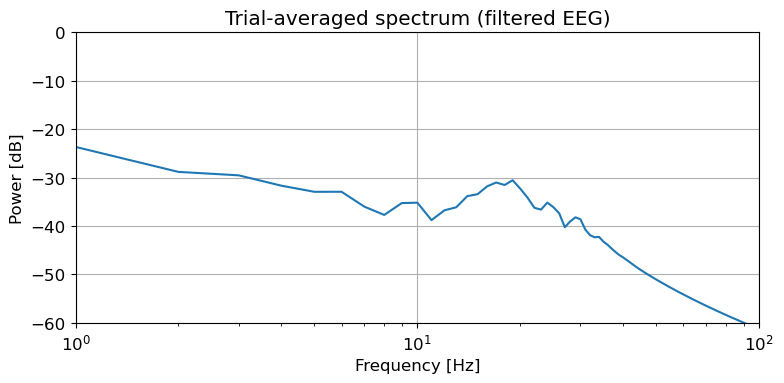

In [62]:
def spectrum(x, t, use_hann=True):
    """
    Compute the one-sided power spectrum of a single trial x
    given its time vector t.
    """
    dt = t[1] - t[0]
    T = len(t) * dt                   # total duration
    x0 = x - x.mean()                 # remove DC

    if use_hann:
        window = np.hanning(len(x))
        xw = window * x0
    else:
        xw = x0

    xf = np.fft.rfft(xw)              # one-sided FFT
    Sxx = 2 * (dt**2) / T * (xf * np.conj(xf))

    return Sxx.real

# Frequency axis consistent with rfft
dt = t[1] - t[0]
N = len(t)
freqs = np.fft.rfftfreq(N, d=dt)
df = freqs[1] - freqs[0]

# Compute spectrum for each filtered trial (no Hann here)
Sxx_trials = np.array([spectrum(trial, t, use_hann=False) for trial in eeg_lo])
Sxx_mean = Sxx_trials.mean(axis=0)

plt.figure()
plt.semilogx(freqs, 10 * np.log10(Sxx_mean))
plt.xlim([df, 100])
plt.ylim([-60, 0])
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Trial-averaged spectrum (filtered EEG)")
plt.tight_layout()
plt.show()

## Summary
We began by inspecting single trials and computing the ERP and average spectrum, which revealed strong 60 Hz contamination and only weak hints of an evoked response. This led to the hypothesis that any real evoked effect might be masked by noise.

To address this, we introduced filtering—first through simple “naive” filters to build intuition, exploring their impulse responses, their behavior in the time and frequency domains, and the trade-offs they introduce. These examples showed why sharp frequency-domain edges (as in the rectangular filter) can create unwanted ringing in time.

We then moved to a more practical solution: a finite impulse response (FIR) filter. Using standard Python tools, we examined its magnitude and phase responses and highlighted the value of zero-phase filtering.

Finally, after low-pass filtering the EEG data, the evoked response became clearly visible—confirming that it had been hidden beneath the original 60 Hz noise.

Overall, this notebook introduced essential filtering concepts aimed at providing enough intuition to use real-world filters confidently and appropriately. For further details, check:

> Widmann, A., Schröger, E., & Maess, B. (2015). *Filters: When, Why, and How (Not) to Use Them*. **Neuron**, 102(2), 280–293. https://doi.org/10.1016/j.neuron.2019.02.039